# Задача 7. Методи регресійного аналізу в Python

Дані Ames Housing із lab3. Ціль — SalePrice; Id вилучено, MSSubClass — категорія.
Регресія: 80% навчання, 20% валідація. Класифікація: 60% навчання, 20% вибір порогу, 20% перевірка.
Усі розбиття фіксовані; виконано також необов'язкові пункти.

In [16]:
import sys
import importlib.util
import subprocess

if importlib.util.find_spec("sklearn") is None:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "scikit-learn"])

from pathlib import Path
import time
import tempfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from scipy.linalg import qr
import statsmodels.api as sm
from sklearn.base import BaseEstimator, TransformerMixin, clone
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import Lasso, LassoCV, Ridge, LinearRegression, lasso_path
from sklearn.model_selection import train_test_split, KFold, GridSearchCV
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import BaggingRegressor, RandomForestRegressor
from sklearn.metrics import mean_squared_error, r2_score, confusion_matrix
from sklearn.metrics import roc_curve, roc_auc_score, accuracy_score
from joblib import Memory
from IPython.display import display

SEED = 42
DATA = Path("../lab3/house-prices-advanced-regression-techniques")
if not DATA.exists():
    DATA = Path("lab3/house-prices-advanced-regression-techniques")
plt.style.use("grayscale")
plt.rcParams.update({"font.family": "DejaVu Serif", "figure.dpi": 120,
                     "figure.facecolor": "white", "axes.facecolor": "white",
                     "savefig.facecolor": "white", "font.size": 10})
pd.set_option("display.max_columns", 8)
pd.set_option("display.precision", 6)
results = {}
tables = {}

In [17]:
df = pd.read_csv(DATA / "train.csv", keep_default_na=False)
for col in ["LotFrontage", "MasVnrArea", "GarageYrBlt"]:
    df[col] = pd.to_numeric(df[col].replace({"NA": np.nan, "": np.nan}))
df["Electrical"] = df["Electrical"].replace({"NA": np.nan, "": np.nan})
df.loc[(df["GarageType"] == "NA") & df["GarageYrBlt"].isna(), "GarageYrBlt"] = 0
df["MSSubClass"] = df["MSSubClass"].astype(str)
X = df.drop(columns=["Id", "SalePrice"])
y = df["SalePrice"].astype(float)
binary = (y > 130000).astype(int).rename("Y")
train_ix, valid_ix = train_test_split(
    df.index, test_size=0.2, stratify=binary, random_state=SEED
)
X_train, X_valid = X.loc[train_ix], X.loc[valid_ix]
y_train, y_valid = y.loc[train_ix], y.loc[valid_ix]
num_cols = X.select_dtypes(include="number").columns.tolist()
cat_cols = [c for c in X if c not in num_cols]
print("Рядків:", len(df), "; характеристик:", X.shape[1])
print("Навчання:", len(train_ix), "; валідація:", len(valid_ix))
display(binary.value_counts().sort_index().rename("Кількість").to_frame())

Рядків: 1460 ; характеристик: 79
Навчання: 1168 ; валідація: 292


,Кількість
Y,
0,376
1,1084


## (1) Lasso та Ridge
### (а) Принцип Lasso

$$
\min_{\beta_0,\beta}\frac1{2n}\sum_i(y_i-\beta_0-x_i'\beta)^2+
\alpha\sum_j|\beta_j|.
$$

Штраф L1 стискає коефіцієнти, частину робить нульовими. За колінеарності або p>n OLS не має єдиного розв'язку;
Lasso можна оцінити, хоча його розв'язок також не завжди єдиний. Модуль недиференційовний у нулі,
тому загального матричного розв'язку немає; sklearn використовує координатний спуск.
Ridge мінімізує RSS+α‖β‖² і має розв'язок $(X'X+\alpha I)^{-1}X'y$ для центрованих даних.

### (б) Масштабування та категорії

Числові ознаки стандартизую; інакше одиниці вимірювання змінювали б силу штрафу.
Dummy залишаю 0/1: їх можна масштабувати, але це змінює штраф для рідкісних рівнів.
FireplaceQu та інші категорії кодує OneHotEncoder, зокрема окремий рівень NA.
Імпутація й масштабування навчаються всередині кожного CV-блоку.
QR вилучає лише лінійно залежні колонки, щоб коефіцієнти OLS були визначені.

In [18]:
class FullRank(BaseEstimator, TransformerMixin):
    def fit(self, X, y=None):
        self.feature_names_in_ = np.asarray(X.columns, dtype=object)
        a = X.to_numpy(dtype=float)
        _, r, piv = qr(a - a.mean(axis=0), mode="economic", pivoting=True)
        rank = np.sum(np.abs(np.diag(r)) > abs(r[0, 0]) * 1e-9)
        self.columns_ = np.sort(piv[:rank])
        return self

    def transform(self, X):
        return X.iloc[:, self.columns_]

    def get_feature_names_out(self, input_features=None):
        return self.feature_names_in_[self.columns_]

numeric_pipe = Pipeline([("impute", SimpleImputer(strategy="median")),
                         ("scale", StandardScaler())])
category_pipe = Pipeline([("impute", SimpleImputer(strategy="most_frequent")),
                          ("encode", OneHotEncoder(handle_unknown="ignore",
                                                    sparse_output=False))])
preprocessor = ColumnTransformer([
    ("num", numeric_pipe, num_cols), ("cat", category_pipe, cat_cols)
]).set_output(transform="pandas")
memory = Memory(Path(tempfile.gettempdir()) / "lab4-cache", verbose=0)

def regular_pipeline(model):
    return Pipeline([("prep", clone(preprocessor)), ("rank", FullRank()),
                     ("model", model)], memory=memory)

basis = Pipeline([("prep", clone(preprocessor)), ("rank", FullRank())])
Z_train = basis.fit_transform(X_train)
Z_valid = basis.transform(X_valid)
print("Після кодування:", basis.named_steps["prep"].transform(X_train).shape[1])
print("Незалежних колонок:", Z_train.shape[1])
tables["encoding"] = {"encoded": basis.named_steps["prep"].transform(X_train).shape[1],
                       "rank": Z_train.shape[1]}

Після кодування: 310
Незалежних колонок: 256


### (в) Lasso: шлях коефіцієнтів та вибір α

LassoCV обчислює попередній шлях. Остаточний α перевіряю п'ятикратною CV всієї Pipeline,
щоб імпутація, масштабування і QR не використовували контрольний блок.

LassoCV α = 177.827941
Pipeline CV α = 237.137371
Ненульових коефіцієнтів: 71


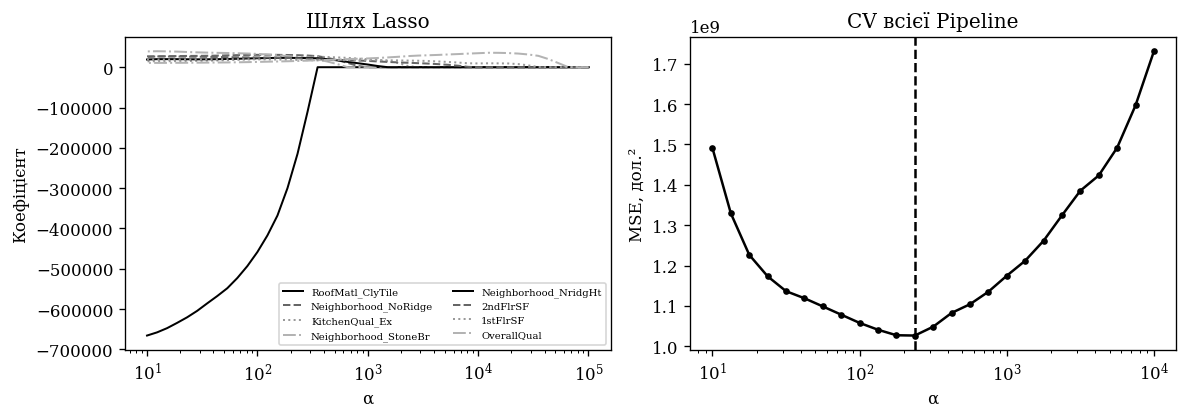

In [19]:
cv5 = KFold(5, shuffle=True, random_state=SEED)
lasso_grid = np.logspace(1, 4, 25)
lasso_cv = LassoCV(alphas=lasso_grid, cv=cv5, max_iter=50000,
                   tol=1e-5, n_jobs=1).fit(Z_train, y_train)
lasso_search = GridSearchCV(
    regular_pipeline(Lasso(max_iter=50000, tol=1e-5)),
    {"model__alpha": lasso_grid}, cv=cv5, scoring="neg_mean_squared_error",
    n_jobs=1, error_score="raise"
).fit(X_train, y_train)
lasso = lasso_search.best_estimator_
lasso_alpha = lasso_search.best_params_["model__alpha"]
lasso_names = lasso.named_steps["rank"].get_feature_names_out()
lasso_coef = pd.Series(lasso.named_steps["model"].coef_, index=lasso_names)
print(f"LassoCV α = {lasso_cv.alpha_:.6f}")
print(f"Pipeline CV α = {lasso_alpha:.6f}")
print("Ненульових коефіцієнтів:", int((lasso_coef.abs() > 1e-8).sum()))

path_alphas, path_coef, _ = lasso_path(
    Z_train.to_numpy() - Z_train.to_numpy().mean(axis=0),
    y_train.to_numpy() - y_train.mean(), alphas=np.logspace(1, 5, 45),
    max_iter=50000, tol=1e-5
)
top_path = lasso_coef.abs().nlargest(8).index
fig, axes = plt.subplots(1, 2, figsize=(10, 3.6))
styles = ["-", "--", ":", "-."]
for j, name in enumerate(top_path):
    i = list(Z_train.columns).index(name)
    axes[0].plot(path_alphas, path_coef[i], styles[j % 4],
                 lw=1.2, label=name.replace("num__", "").replace("cat__", ""))
axes[0].set(xscale="log", xlabel="α", ylabel="Коефіцієнт", title="Шлях Lasso")
axes[0].legend(fontsize=6, ncol=2)
scores = lasso_search.cv_results_
axes[1].plot(lasso_grid, -scores["mean_test_score"], "k.-")
axes[1].axvline(lasso_alpha, color="black", ls="--")
axes[1].set(xscale="log", xlabel="α", ylabel="MSE, дол.²", title="CV всієї Pipeline")
fig.tight_layout()
plt.show()
results.update(lasso_alpha=lasso_alpha, lasso_cv_alpha=lasso_cv.alpha_,
               lasso_nonzero=int((lasso_coef.abs() > 1e-8).sum()))

Рекомендований α=237.137371 за CV Pipeline. Ненульових коефіцієнтів — 71.
Зі збільшенням α коефіцієнти стискаються до нуля.

### (г) Ridge, OLS та дисперсії

Підбираю Ridge тією самою CV. Для спільної матриці X порівнюю умовні дисперсії коефіцієнтів:
Cov(OLS)=σ²(X′X)⁻¹; Cov(Ridge)=σ²(X′X+αI)⁻¹X′X(X′X+αI)⁻¹.
σ² оцінюю з залишків OLS; формули припускають сталу дисперсію похибок.

In [20]:
ridge_grid = np.logspace(-2, 5, 25)
ridge_search = GridSearchCV(
    regular_pipeline(Ridge(solver="cholesky")), {"model__alpha": ridge_grid},
    cv=cv5, scoring="neg_mean_squared_error", n_jobs=1, error_score="raise"
).fit(X_train, y_train)
ridge = ridge_search.best_estimator_
ridge_alpha = ridge_search.best_params_["model__alpha"]
ols = regular_pipeline(LinearRegression()).fit(X_train, y_train)
for model in [lasso, ridge, ols]:
    assert np.array_equal(model.named_steps["rank"].get_feature_names_out(), Z_train.columns)
ols_coef = pd.Series(ols.named_steps["model"].coef_, index=Z_train.columns)
ridge_coef = pd.Series(ridge.named_steps["model"].coef_, index=Z_train.columns)
centered = Z_train.to_numpy() - Z_train.to_numpy().mean(axis=0)
_, singular, vt = np.linalg.svd(centered, full_matrices=False)
resid = y_train - ols.predict(X_train)
sigma2 = np.sum(resid**2) / (len(y_train) - Z_train.shape[1] - 1)
var_ols = sigma2 * ((vt.T**2) @ (1 / singular**2))
var_ridge = sigma2 * ((vt.T**2) @ (singular**2 / (singular**2 + ridge_alpha)**2))
variance = pd.DataFrame({"Ознака": Z_train.columns, "β OLS": ols_coef.values,
                         "β Ridge": ridge_coef.values, "Var OLS": var_ols,
                         "Var Ridge": var_ridge}).set_index("Ознака")
variance_top = variance.loc[ols_coef.abs().nlargest(10).index]
display(variance_top)
regression_scores = []
for label, model in [("OLS", ols), ("Lasso", lasso), ("Ridge", ridge)]:
    pred = model.predict(X_valid)
    regression_scores.append({"Модель": label, "MSE": mean_squared_error(y_valid, pred),
                               "RMSE": np.sqrt(mean_squared_error(y_valid, pred)),
                               "R²": r2_score(y_valid, pred)})
display(pd.DataFrame(regression_scores))
print(f"Ridge α = {ridge_alpha:.6f}")
results.update(ridge_alpha=ridge_alpha,
               variance_ratio=float(np.median(var_ridge / var_ols)))
tables["variance"] = variance_top.rename_axis("Ознака").reset_index().to_dict("records")
tables["regression_scores"] = regression_scores

,β OLS,β Ridge,Var OLS,Var Ridge
cat__PoolQC_Gd,-5.148578e+06,-5353.738221,5.092097e+11,95821.285793
cat__PoolQC_Fa,-4.557161e+06,-251.032472,3.937076e+11,104730.866812
cat__PoolQC_Ex,-3.675429e+06,4421.709776,2.715528e+11,119666.919631
cat__RoofMatl_ClyTile,1.021909e+06,-6258.553711,6.468386e+10,53920.927346
cat__MiscFeature_Shed,-8.524635e+05,-103.756963,1.687539e+10,714933.692735
cat__MiscFeature_NA,-8.497546e+05,328.510119,1.697141e+10,659395.747683
cat__MiscFeature_Othr,-8.274097e+05,184.541032,1.929302e+10,94540.563376
num__PoolArea,2.945242e+05,244.298651,1.619007e+09,384576.520625
cat__GarageQual_Ex,1.740819e+05,2087.598963,1.611892e+09,245336.469325
cat__GarageCond_TA,1.507824e+05,1222.394692,1.180065e+09,993383.768913


,Модель,MSE,RMSE,R²
0,OLS,1.243091e+10,111494.000283,-0.973907
1,Lasso,1.168455e+09,34182.666805,0.814461
2,Ridge,1.236475e+09,35163.543005,0.803660


Ridge α = 61.896582


Ridge α=61.896582. Медіанне відношення Var(Ridge)/Var(OLS)=0.002684.
Штраф додає зміщення, зате зменшує дисперсію; прогнозну перевагу перевіряю на валідації.
OLS нестійка на рідкісних категоріях басейну й матеріалу даху; регуляризація суттєво зменшила валідаційну MSE.

## (2) Дерева та ансамблі
### (а–б) Перше розщеплення за GrLivArea

$$
\min_s\left[\sum_{x_i\le s}(y_i-\bar{y}_L)^2+
\sum_{x_i>s}(y_i-\bar{y}_R)^2\right].
$$

Сортую площі й перевіряю середини між сусідніми різними значеннями.
Жадібний алгоритм обирає найкращий поточний розріз, не оптимізуючи все майбутнє дерево.

Ручний поріг = 1825.000000; sklearn = 1825.000000
RSS = 4977562477455.613281


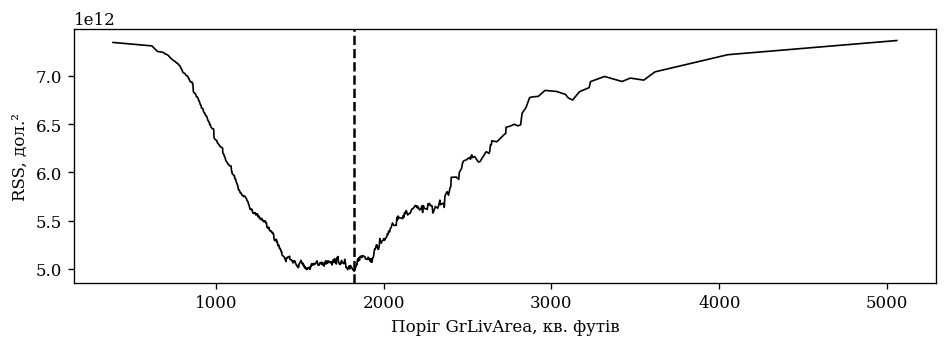

In [21]:
order = np.argsort(X_train["GrLivArea"].to_numpy(), kind="stable")
area = X_train["GrLivArea"].to_numpy(dtype=float)[order]
price = y_train.to_numpy()[order]
cuts = np.flatnonzero(area[:-1] < area[1:]) + 1
grid = (area[cuts-1] + area[cuts]) / 2
sums, squares = np.cumsum(price), np.cumsum(price**2)
n = len(price)
rss_left = squares[cuts-1] - sums[cuts-1]**2 / cuts
rss_right = (squares[-1] - squares[cuts-1]
             - (sums[-1]-sums[cuts-1])**2 / (n-cuts))
rss_grid = rss_left + rss_right
best = np.argmin(rss_grid)
split = grid[best]
stump = DecisionTreeRegressor(max_depth=1, random_state=SEED)
stump.fit(X_train[["GrLivArea"]], y_train)
assert np.isclose(split, stump.tree_.threshold[0])
assert np.isclose(rss_grid[best], np.sum((y_train-stump.predict(X_train[["GrLivArea"]]))**2))
print(f"Ручний поріг = {split:.6f}; sklearn = {stump.tree_.threshold[0]:.6f}")
print(f"RSS = {rss_grid[best]:.6f}")
fig, ax = plt.subplots(figsize=(8, 3))
ax.plot(grid, rss_grid, "k-", lw=1)
ax.axvline(split, ls="--", color="black")
ax.set(xlabel="Поріг GrLivArea, кв. футів", ylabel="RSS, дол.²")
fig.tight_layout()
plt.show()
results.update(split=split, split_rss=rss_grid[best], split_left=int(cuts[best]),
               split_right=int(n-cuts[best]))

Поріг — 1825.000000 кв. футів; RSS=4977562477455.613281. Ручний результат збігається зі sklearn.

### (в) OverallQual та категорії

OverallQual — порядкова ознака; перевіряються пороги 1.5, 2.5, …, 9.5.
Для номінальних категорій використовую OneHotEncoder: довільні числові коди створили б штучний порядок.
### (г–д) Дерево до 10 розщеплень та стрижка

max_leaf_nodes=11 дає щонайбільше 10 внутрішніх вузлів.
Cost-complexity мінімізує R(T)+α|листи|. Більший ccp_alpha скорочує дерево;
за α=0 залишається дерево з попереднім обмеженням.

In [22]:
qual_stump = DecisionTreeRegressor(max_depth=1, random_state=SEED)
qual_stump.fit(X_train[["OverallQual"]], y_train)
print("Поріг OverallQual:", qual_stump.tree_.threshold[0])
tree_preprocessor = ColumnTransformer([
    ("num", SimpleImputer(strategy="median"), num_cols),
    ("cat", clone(category_pipe), cat_cols)
]).set_output(transform="pandas")
T_train = tree_preprocessor.fit_transform(X_train)
T_valid = tree_preprocessor.transform(X_valid)
tree = DecisionTreeRegressor(max_leaf_nodes=11, random_state=SEED).fit(T_train, y_train)
assert tree.get_n_leaves() <= 11
path = tree.cost_complexity_pruning_path(T_train, y_train)
pruning = []
for alpha in np.unique(path.ccp_alphas):
    model = DecisionTreeRegressor(max_leaf_nodes=11, ccp_alpha=alpha,
                                   random_state=SEED).fit(T_train, y_train)
    pruning.append({"ccp_alpha": alpha, "Листів": model.get_n_leaves(),
                    "Глибина": model.get_depth(),
                    "MSE валідації": mean_squared_error(y_valid, model.predict(T_valid))})
pruning = pd.DataFrame(pruning)
display(pruning)
print("Початкове дерево: листів", tree.get_n_leaves(), "; розщеплень", tree.tree_.node_count-tree.get_n_leaves())
results.update(qual_split=qual_stump.tree_.threshold[0], tree_leaves=tree.get_n_leaves(),
               tree_depth=tree.get_depth())
tables["pruning"] = pruning.to_dict("records")

Поріг OverallQual: 7.5


,ccp_alpha,Листів,Глибина,MSE валідації
0,0.000000e+00,11,5,1.832012e+09
1,7.412561e+07,10,4,1.784455e+09
2,9.068350e+07,9,4,1.886270e+09
3,9.099679e+07,8,3,1.848711e+09
4,9.527412e+07,7,3,2.053890e+09
5,1.334261e+08,6,3,2.109701e+09
6,1.557075e+08,5,3,2.580749e+09
7,2.355558e+08,4,2,2.851142e+09
8,3.895861e+08,3,2,3.294681e+09
9,7.543590e+08,2,1,3.941569e+09


Початкове дерево: листів 11 ; розщеплень 10


### (е) Поліпшення в корені

$$
\Delta I=I_0-\frac{n_L}{n_0}I_L-\frac{n_R}{n_0}I_R.
$$

Для squared_error неоднорідність — середній квадрат відхилень від середнього вузла.
У корені n₀/n=1; зменшення RSS дорівнює n·ΔI.

In [23]:
t = tree.tree_
left, right = t.children_left[0], t.children_right[0]
n0, nl, nr = t.n_node_samples[[0, left, right]]
i0, il, ir = t.impurity[[0, left, right]]
gain = i0 - nl/n0*il - nr/n0*ir
root_name = T_train.columns[t.feature[0]]
print(f"Корінь: {root_name} <= {t.threshold[0]:.6f}")
print(f"ΔI = {i0:.6f} - ({nl}/{n0})*{il:.6f} - ({nr}/{n0})*{ir:.6f} = {gain:.6f}")
print(f"Зменшення RSS = {n0*gain:.6f}")
results.update(root_feature=root_name, root_cut=t.threshold[0], gain=gain,
               root_i=i0, left_i=il, right_i=ir, root_n=int(n0),
               left_n=int(nl), right_n=int(nr))

Корінь: num__OverallQual <= 7.500000
ΔI = 6307898975.940865 - (991/1168)*2428149108.419971 - (177/1168)*8330148444.290970 = 2985354420.218525
Зменшення RSS = 3486893962815.237305


### (ж) Важливість ознак

MDI дерева — нормована сума зменшень неоднорідності. Для OLS і Lasso використовую частки |β|·sd(x).
Індикатори підсумовую за початковою змінною. Ці величини мають різний зміст і не є причинними ефектами.

In [24]:
def source_feature(name):
    kind, value = name.split("__", 1)
    if kind == "num":
        return value
    return next(c for c in sorted(cat_cols, key=len, reverse=True)
                if value.startswith(c + "_"))

def coefficient_importance(coef):
    effect = coef.abs() * Z_train.std(ddof=0)
    grouped = effect.groupby([source_feature(c) for c in effect.index]).sum()
    return grouped / grouped.sum()

encoded_tree_imp = pd.Series(tree.feature_importances_, index=T_train.columns)
encoded_top = encoded_tree_imp.nlargest(10).index
tree_coefficients = pd.DataFrame({"MDI": encoded_tree_imp.reindex(encoded_top),
                                  "β Lasso": lasso_coef.reindex(encoded_top),
                                  "β OLS": ols_coef.reindex(encoded_top)})
display(tree_coefficients)
tables["tree_coefficients"] = tree_coefficients.rename_axis("Ознака").reset_index().to_dict("records")
tree_imp = encoded_tree_imp.copy()
tree_imp = tree_imp.groupby([source_feature(c) for c in tree_imp.index]).sum()
importance = pd.concat({"OLS": coefficient_importance(ols_coef),
                        "Lasso": coefficient_importance(lasso_coef),
                        "Дерево": tree_imp}, axis=1).fillna(0)
tree_top = importance.loc[tree_imp.nlargest(10).index]
display(tree_top)
tables["tree_importance"] = tree_top.rename_axis("Ознака").reset_index().to_dict("records")

,MDI,β Lasso,β OLS
num__OverallQual,0.825023,15545.272076,10265.115665
num__GrLivArea,0.107567,NaN,NaN
num__2ndFlrSF,0.031110,22038.739875,26019.750029
num__GarageCars,0.018181,9424.876748,3382.258819
num__TotalBsmtSF,0.018118,7505.819161,18523.890192
num__LotFrontage,0.000000,-868.080029,145.985524
num__LotArea,0.000000,3747.575948,10098.977559
num__OverallCond,0.000000,6057.779411,6445.572092
num__YearBuilt,0.000000,8117.825694,9772.360358
num__YearRemodAdd,0.000000,1118.929308,2323.484395


,OLS,Lasso,Дерево
OverallQual,0.004202,0.071963,0.825023
GrLivArea,0.000000,0.000000,0.107567
2ndFlrSF,0.010652,0.102024,0.031110
GarageCars,0.001385,0.043630,0.018181
TotalBsmtSF,0.007583,0.034747,0.018118
1stFlrSF,0.007870,0.083623,0.000000
3SsnPorch,0.000088,0.000000,0.000000
Alley,0.000244,0.000000,0.000000
BedroomAbvGr,0.001636,0.020509,0.000000
BldgType,0.004201,0.021647,0.000000


### (з–и) Бутстреп, 1000 вибірок

Беру перші 10 числових характеристик і додаю Street_Pave, бо Street є категоріальною.
Використовую df.sample(replace=True), зберігаю коефіцієнти LotArea та Street_Pave.
Медіани навчальної вибірки фіксовані. Порівнюю percentile-інтервали з класичними t-інтервалами OLS.

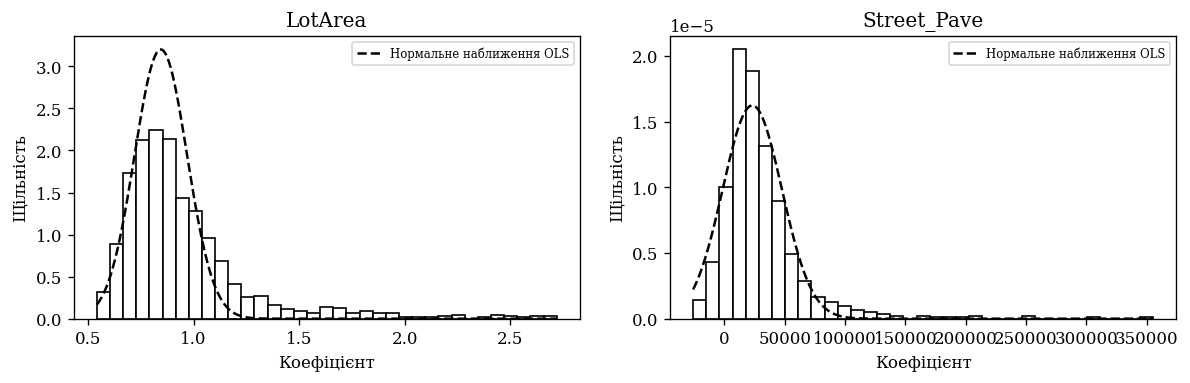

,Параметр,OLS,Bootstrap low,Bootstrap high,OLS low,OLS high,Оцінено вибірок
0,LotArea,0.844555,0.618176,1.889246,0.600062,1.089047,1000
1,Street_Pave,23099.248028,-11727.009934,113265.374561,-25110.536301,71309.032356,950


Перші 10 числових ознак: ['LotFrontage', 'LotArea', 'OverallQual', 'OverallCond', 'YearBuilt', 'YearRemodAdd', 'MasVnrArea', 'BsmtFinSF1', 'BsmtFinSF2', 'BsmtUnfSF']
Street у навчанні: {'Pave': 1165, 'Grvl': 3}


In [25]:
boot_cols = num_cols[:10]
boot_imputer = SimpleImputer(strategy="median")
boot_X = pd.DataFrame(boot_imputer.fit_transform(X_train[boot_cols]),
                       index=train_ix, columns=boot_cols)
boot_X["Street_Pave"] = (X_train["Street"] == "Pave").astype(float)
boot_data = boot_X.assign(SalePrice=y_train)
boot_ols = sm.OLS(y_train, sm.add_constant(boot_X)).fit()
boot_coef = np.full((1000, 2), np.nan)
rng = np.random.default_rng(SEED)
for i in range(1000):
    draw = boot_data.sample(n=len(boot_data), replace=True,
                            random_state=int(rng.integers(0, 2**31-1)))
    model = LinearRegression().fit(draw[boot_X.columns], draw["SalePrice"])
    boot_coef[i, 0] = model.coef_[boot_X.columns.get_loc("LotArea")]
    if draw["Street_Pave"].nunique() == 2:
        boot_coef[i, 1] = model.coef_[-1]
bootstrap_rows = []
fig, axes = plt.subplots(1, 2, figsize=(10, 3.3))
for j, name in enumerate(["LotArea", "Street_Pave"]):
    values = boot_coef[:, j]
    values = values[np.isfinite(values)]
    low, high = np.percentile(values, [2.5, 97.5])
    classic_low, classic_high = boot_ols.conf_int().loc[name]
    bootstrap_rows.append({"Параметр": name, "OLS": boot_ols.params[name],
                            "Bootstrap low": low, "Bootstrap high": high,
                            "OLS low": classic_low, "OLS high": classic_high,
                            "Оцінено вибірок": len(values)})
    axes[j].hist(values, bins=35, density=True, color="white", edgecolor="black")
    xgrid = np.linspace(min(values.min(), classic_low), max(values.max(), classic_high), 300)
    axes[j].plot(xgrid, stats.norm.pdf(xgrid, boot_ols.params[name], boot_ols.bse[name]),
                 "k--", label="Нормальне наближення OLS")
    axes[j].set(title=name, xlabel="Коефіцієнт", ylabel="Щільність")
    axes[j].legend(fontsize=7)
fig.tight_layout()
plt.show()
bootstrap_table = pd.DataFrame(bootstrap_rows)
display(bootstrap_table)
print("Перші 10 числових ознак:", boot_cols)
print("Street у навчанні:", X_train["Street"].value_counts().to_dict())
tables["bootstrap"] = bootstrap_rows
tables["boot_columns"] = boot_cols

Бутстреп показує чутливість до складу вибірки. Якщо в повторі немає обох рівнів Street,
її коефіцієнт не ідентифікований: такий повтор не включаю до її інтервалу.
Відмінності від класичного інтервалу можливі через викиди, рідкісну категорію та неоднакову дисперсію.

### (і–к) Беггінг та Random Forest

Порівнюю глибокі дерева. У беггінгу доступні всі ознаки, у лісі — 1/3 ознак у кожному вузлі.
Час вимірюю time.time(), обидва методи на одному процесорному потоці.

,Модель,Дерев,MSE навчання,MSE валідації,"Час, с"
0,Bagging,10,1.528540e+08,1.467597e+09,0.158582
1,Random Forest,10,1.514291e+08,1.330280e+09,0.057871
2,Bagging,30,1.407158e+08,1.357265e+09,0.448368
3,Random Forest,30,1.261071e+08,1.243029e+09,0.170962
4,Bagging,60,1.220607e+08,1.364305e+09,0.872317
5,Random Forest,60,1.098190e+08,1.174516e+09,0.336633
6,Bagging,100,1.203620e+08,1.339917e+09,1.441274
7,Random Forest,100,1.095770e+08,1.237292e+09,0.558240
8,Bagging,200,1.212433e+08,1.369445e+09,2.860752
9,Random Forest,200,1.095335e+08,1.257852e+09,1.112500


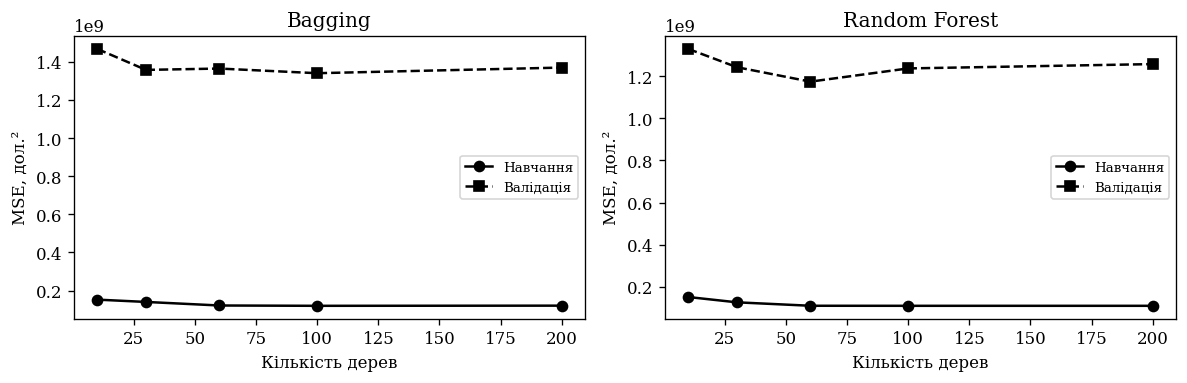

,OLS,Lasso,Дерево,Random Forest
OverallQual,0.004202,0.071963,0.825023,0.256404
GarageCars,0.001385,0.043630,0.018181,0.123564
GrLivArea,0.000000,0.000000,0.107567,0.098906
ExterQual,0.005879,0.014037,0.000000,0.068044
TotalBsmtSF,0.007583,0.034747,0.018118,0.064744
1stFlrSF,0.007870,0.083623,0.000000,0.045427
YearBuilt,0.004001,0.037580,0.000000,0.038490
BsmtQual,0.007888,0.046891,0.000000,0.034624
GarageArea,0.001090,0.000000,0.000000,0.032072
FullBath,0.000830,0.014722,0.000000,0.025126


In [26]:
bagging = BaggingRegressor(
    estimator=DecisionTreeRegressor(random_state=SEED), n_estimators=10,
    bootstrap=True, max_features=1.0, random_state=SEED, n_jobs=1, warm_start=True
)
forest = RandomForestRegressor(n_estimators=10, max_features=1/3,
                               random_state=SEED, n_jobs=1, warm_start=True)
ensemble_rows = []
elapsed = {"Bagging": 0.0, "Random Forest": 0.0}
for count in [10, 30, 60, 100, 200]:
    for label, model in [("Bagging", bagging), ("Random Forest", forest)]:
        model.set_params(n_estimators=count)
        start = time.time()
        model.fit(T_train, y_train)
        elapsed[label] += time.time() - start
        ensemble_rows.append({"Модель": label, "Дерев": count,
                               "MSE навчання": mean_squared_error(y_train, model.predict(T_train)),
                               "MSE валідації": mean_squared_error(y_valid, model.predict(T_valid)),
                               "Час, с": elapsed[label]})
ensembles = pd.DataFrame(ensemble_rows)
display(ensembles)
fig, axes = plt.subplots(1, 2, figsize=(10, 3.3))
for ax, label in zip(axes, ["Bagging", "Random Forest"]):
    part = ensembles[ensembles["Модель"] == label]
    ax.plot(part["Дерев"], part["MSE навчання"], "ko-", label="Навчання")
    ax.plot(part["Дерев"], part["MSE валідації"], "ks--", label="Валідація")
    ax.set(title=label, xlabel="Кількість дерев", ylabel="MSE, дол.²")
    ax.legend(fontsize=8)
fig.tight_layout()
plt.show()
forest_imp = pd.Series(forest.feature_importances_, index=T_train.columns)
forest_imp = forest_imp.groupby([source_feature(c) for c in forest_imp.index]).sum()
importance["Random Forest"] = forest_imp
final_importance = importance.loc[forest_imp.nlargest(10).index]
display(final_importance)
tables["ensembles"] = ensemble_rows
tables["final_importance"] = final_importance.rename_axis("Ознака").reset_index().to_dict("records")
for label, short in [("Bagging", "bag"), ("Random Forest", "rf")]:
    rows = ensembles[ensembles["Модель"] == label]
    best_row = rows.loc[rows["MSE валідації"].idxmin()]
    results[short+"_best_n"] = int(best_row["Дерев"])
    results[short+"_best_mse"] = best_row["MSE валідації"]
    results[short+"_time"] = elapsed[label]

Найкраще на цій сітці: Bagging — 100 дерев, Random Forest — 60.
Більше дерев переважно стабілізують прогноз; навчальна й валідаційна помилки різняться.
Ліс перевіряє менше ознак на вузол і зменшує залежність між деревами.
Менша кількість потрібних дерев або швидший час не гарантовані: це перевіряється таблицею.
MDI може завищувати роль неперервних ознак; нуль OLS також може означати вилучену QR-залежну колонку.

## (3) Бінарна класифікація

Y=1, якщо SalePrice>130000; інакше Y=0.
### (а) Logit із backward AIC

Відбір починається лише з числових характеристик. Прибираю точні залежності й ознаку з розділенням класів,
далі вилучаю по одній змінній, поки AIC зменшується. Відбір використовує лише 60% даних.

In [27]:
fit_ix, calibration_ix = train_test_split(
    train_ix, test_size=0.25, stratify=binary.loc[train_ix], random_state=SEED+1
)
logit_cols = num_cols.copy()
separated = []
for col in logit_cols[:]:
    nonzero = X.loc[fit_ix, col].fillna(0) != 0
    if nonzero.sum() == 0 or binary.loc[fit_ix[nonzero]].nunique() == 1:
        separated.append(col)
        logit_cols.remove(col)
logit_imputer = SimpleImputer(strategy="median")
logit_scaler = StandardScaler()
raw_fit = logit_imputer.fit_transform(X.loc[fit_ix, logit_cols])
logit_scaler.fit(raw_fit)

def logit_matrix(indices):
    filled = logit_imputer.transform(X.loc[indices, logit_cols])
    return pd.DataFrame(logit_scaler.transform(filled), index=indices, columns=logit_cols)

L_fit = logit_matrix(fit_ix)
rank_logit = FullRank().fit(L_fit)
active = list(rank_logit.get_feature_names_out())
logit_history = []
while True:
    current = sm.Logit(binary.loc[fit_ix], sm.add_constant(L_fit[active])).fit(disp=False, maxiter=150)
    if not current.mle_retvals["converged"]:
        raise RuntimeError("Logit не збігся")
    candidates = []
    for drop in active:
        cols = [c for c in active if c != drop]
        candidate = sm.Logit(binary.loc[fit_ix], sm.add_constant(L_fit[cols])).fit(disp=False, maxiter=150)
        if candidate.mle_retvals["converged"] and np.isfinite(candidate.bse).all():
            candidates.append((candidate.aic, drop))
    if not candidates or min(candidates)[0] >= current.aic - 1e-7:
        final_logit = current
        break
    best_aic, drop = min(candidates)
    logit_history.append({"Крок": len(logit_history)+1, "Вилучено": drop, "AIC": best_aic})
    active.remove(drop)
assert np.isfinite(final_logit.bse).all()
display(pd.DataFrame(logit_history))
logit_table = pd.DataFrame({"β (z)": final_logit.params,
                            "SE": final_logit.bse, "p": final_logit.pvalues})
display(logit_table)
print("Вилучено через розділення / відсутність варіації:", separated)
print(f"Фінальний AIC = {final_logit.aic:.6f}")
tables["logit_history"] = logit_history
tables["logit_coefficients"] = logit_table.rename_axis("Ознака").reset_index().to_dict("records")
tables["separated"] = separated
results.update(logit_aic=final_logit.aic, logit_p=len(active), logit_n=len(fit_ix),
               logit_cal_n=len(calibration_ix), logit_test_n=len(valid_ix))

,Крок,Вилучено,AIC
0,1,GarageYrBlt,386.783076
1,2,LowQualFinSF,384.875091
2,3,3SsnPorch,383.040370
3,4,MasVnrArea,381.211628
4,5,MiscVal,379.413593
5,6,YrSold,377.665508
6,7,EnclosedPorch,376.079195
7,8,WoodDeckSF,374.495499
8,9,GarageCars,373.088701
9,10,BedroomAbvGr,371.610716


,β (z),SE,p
const,4.255794,0.385584,2.525585e-28
LotFrontage,0.506890,0.236859,3.235049e-02
LotArea,1.765502,0.558741,1.578864e-03
OverallQual,1.080821,0.293637,2.325001e-04
OverallCond,0.926435,0.196030,2.289970e-06
YearBuilt,1.671682,0.270230,6.165515e-10
YearRemodAdd,0.272989,0.181658,1.328991e-01
BsmtFinSF1,0.589806,0.273241,3.088427e-02
TotalBsmtSF,0.782820,0.261409,2.747930e-03
1stFlrSF,1.591511,0.340133,2.881613e-06


Вилучено через розділення / відсутність варіації: ['PoolArea']
Фінальний AIC = 364.999381


Фінальна модель: 16 регресорів, AIC=364.999381.
PoolArea вилучено через квазіповне розділення: рідкісні ненульові значення в навчанні належать лише класу 1.
Інтерпретація й подальші прогнози стосуються тільки обраної моделі.

### (б–в) Odds Ratio та знаки

Для кроку Δx шанси змінюються в exp(βΔx) разів; зміна ймовірності залежить від її початкового рівня.
p-значення після відбору є дослідницькими й не враховують пошуку моделі.

In [28]:
scale = pd.Series(logit_scaler.scale_, index=logit_cols)
means = pd.Series(logit_scaler.mean_, index=logit_cols)
raw_beta = final_logit.params.drop("const") / scale[active]
raw_intercept = final_logit.params["const"] - (raw_beta * means[active]).sum()
area_beta = raw_beta["LotArea"]
positive = final_logit.pvalues.index[(final_logit.pvalues < 0.05) & (final_logit.params > 0)]
positive = [c for c in positive if c != "const"]
negative = final_logit.pvalues.index[(final_logit.pvalues < 0.05) & (final_logit.params < 0)]
negative = [c for c in negative if c != "const"]
print(f"β LotArea за кв. фут = {area_beta:.10f}")
print(f"OR за 1 кв. фут = {np.exp(area_beta):.8f}")
print(f"OR за 1000 кв. футів = {np.exp(1000*area_beta):.6f}")
print("Значущі додатні:", positive)
print("Значущі від'ємні:", negative)
tables["positive"] = positive
tables["negative"] = negative
tables["raw_logit"] = {"const": raw_intercept, **raw_beta.to_dict()}
results.update(area_beta=area_beta, area_or=np.exp(area_beta), area_or1000=np.exp(1000*area_beta))

β LotArea за кв. фут = 0.0001845415
OR за 1 кв. фут = 1.00018456
OR за 1000 кв. футів = 1.202667
Значущі додатні: ['LotFrontage', 'LotArea', 'OverallQual', 'OverallCond', 'YearBuilt', 'BsmtFinSF1', 'TotalBsmtSF', '1stFlrSF', '2ndFlrSF', 'BsmtHalfBath']
Значущі від'ємні: ['KitchenAbvGr']


OR для додаткових 1000 кв. футів = 1.202667.
Додатні знаки площі, якості та року побудови узгоджуються з ринковою логікою.
Від'ємний KitchenAbvGr — умовний ефект за фіксованих інших характеристик, а не причинна шкода кухні.

### (г) П'ять будинків та повна формула

In [29]:
def predict_logit(indices):
    return final_logit.predict(sm.add_constant(logit_matrix(indices)[active], has_constant="add"))

prob_valid = predict_logit(valid_ix)
chosen_ix = pd.Index(np.random.default_rng(SEED).choice(valid_ix, size=5, replace=False))
prob_five = predict_logit(chosen_ix)
five = pd.DataFrame({"Id": df.loc[chosen_ix, "Id"], "SalePrice": y.loc[chosen_ix],
                      "Y": binary.loc[chosen_ix], "P(Y=1)": prob_five,
                      "Клас при 0.5": (prob_five >= 0.5).astype(int)})
display(five)
first_ix = chosen_ix[0]
first_values = pd.Series(logit_imputer.transform(X.loc[[first_ix], logit_cols])[0], index=logit_cols)
z_first = raw_intercept + (raw_beta * first_values[active]).sum()
print("Перший Id:", int(df.loc[first_ix, "Id"]))
print(f"z = {raw_intercept:.10f}")
for name in active:
    print(f" + ({raw_beta[name]:.10g})*({first_values[name]:.10g})  [{name}]")
print(f" = {z_first:.10f}")
print(f"p = 1/(1+exp(-({z_first:.10f}))) = {stats.logistic.cdf(z_first):.10f}")
assert np.isclose(stats.logistic.cdf(z_first), prob_five.iloc[0])
tables["five"] = five.to_dict("records")
tables["first_terms"] = [{"name": name, "beta": raw_beta[name], "x": first_values[name]}
                         for name in active]
results.update(first_id=int(df.loc[first_ix, "Id"]), first_z=z_first, first_p=prob_five.iloc[0])

,Id,SalePrice,Y,P(Y=1),Клас при 0.5
1170,1171,171000.0,1,0.958638,1
266,267,185000.0,1,0.998338,1
580,581,181900.0,1,0.999237,1
643,644,152000.0,1,0.951279,1
1200,1201,116050.0,0,0.031388,0


Перший Id: 1171
z = -153.4339018967
 + (0.02413202879)*(76)  [LotFrontage]
 + (0.0001845414869)*(9880)  [LotArea]
 + (0.7870679654)*(6)  [OverallQual]
 + (0.831406865)*(6)  [OverallCond]
 + (0.05534406961)*(1977)  [YearBuilt]
 + (0.01321257026)*(1977)  [YearRemodAdd]
 + (0.001345467607)*(522)  [BsmtFinSF1]
 + (0.001859442839)*(1096)  [TotalBsmtSF]
 + (0.004114676857)*(1118)  [1stFlrSF]
 + (0.004783099287)*(0)  [2ndFlrSF]
 + (0.6488840338)*(1)  [BsmtFullBath]
 + (2.46275961)*(0)  [BsmtHalfBath]
 + (0.7224268235)*(0)  [HalfBath]
 + (-1.416881141)*(1)  [KitchenAbvGr]
 + (0.5137933874)*(1)  [Fireplaces]
 + (0.001637231495)*(358)  [GarageArea]
 = 3.1431455165
p = 1/(1+exp(-(3.1431455165))) = 0.9586377849


Клас прогнозую як 1[p≥c], стандартно c=0.5.

### (д–ж) Матриці помилок, ROC та новий поріг

Поріг Юдена максимізує J=Sensitivity+Specificity−1 на окремих 20% даних.
Матриці й метрики обох порогів оцінюю на інших 20%, які не брали участі у відборі моделі чи порогу.

,Поріг,c,TN,FP,...,TP,Чутливість,Специфічність,Точність
0,0.5,0.500000,61,14,...,205,0.944700,0.813333,0.910959
1,Юден,0.810749,69,6,...,187,0.861751,0.920000,0.876712


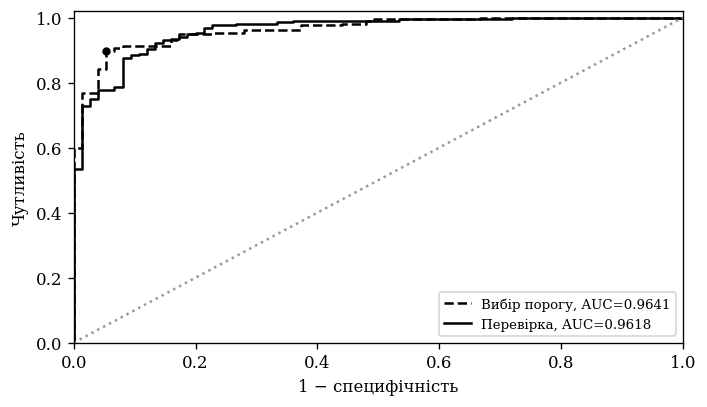

In [30]:
prob_cal = predict_logit(calibration_ix)
fpr_cal, tpr_cal, cutoffs = roc_curve(binary.loc[calibration_ix], prob_cal)
finite = np.isfinite(cutoffs)
best_cut = np.flatnonzero(finite)[np.argmax((tpr_cal-fpr_cal)[finite])]
cutoff = cutoffs[best_cut]
threshold_rows = []
matrices = {}
for label, cut in [("0.5", 0.5), ("Юден", cutoff)]:
    prediction = (prob_valid >= cut).astype(int)
    cm = confusion_matrix(binary.loc[valid_ix], prediction, labels=[0, 1])
    tn, fp, fn, tp = cm.ravel()
    matrices[label] = cm.tolist()
    threshold_rows.append({"Поріг": label, "c": cut, "TN": int(tn), "FP": int(fp),
                            "FN": int(fn), "TP": int(tp),
                            "Чутливість": tp/(tp+fn), "Специфічність": tn/(tn+fp),
                            "Точність": accuracy_score(binary.loc[valid_ix], prediction)})
metrics = pd.DataFrame(threshold_rows)
display(metrics)
test_fpr, test_tpr, _ = roc_curve(binary.loc[valid_ix], prob_valid)
auc_cal = roc_auc_score(binary.loc[calibration_ix], prob_cal)
auc_test = roc_auc_score(binary.loc[valid_ix], prob_valid)
fig, ax = plt.subplots(figsize=(6, 3.5))
ax.plot(fpr_cal, tpr_cal, "k--", label=f"Вибір порогу, AUC={auc_cal:.4f}")
ax.plot(test_fpr, test_tpr, "k-", label=f"Перевірка, AUC={auc_test:.4f}")
ax.plot([0, 1], [0, 1], color="0.6", ls=":")
ax.plot(fpr_cal[best_cut], tpr_cal[best_cut], "ko", ms=4)
ax.set(xlabel="1 − специфічність", ylabel="Чутливість", xlim=(0, 1), ylim=(0, 1.02))
ax.legend(fontsize=8, loc="lower right")
fig.tight_layout()
plt.show()
results.update(cutoff=cutoff, auc_cal=auc_cal, auc_test=auc_test,
               conservative="більш" if cutoff > 0.5 else "менш")
tables["thresholds"] = threshold_rows
tables["matrices"] = matrices

AUC на перевірці = 0.961843. Поріг Юдена = 0.810749; модель стала більш консервативною щодо дорогих будинків.
TN — доступний будинок правильно визначено; FP — доступний помилково названо дорогим;
FN — дорогий помилково названо доступним; TP — дорогий правильно визначено.
Зміна порогу змінює ці помилки, але не коефіцієнти й не ROC-AUC моделі.